In [86]:

from typing import Callable, Tuple, List, Dict
import json
from pathlib import Path
import numpy as np
from scipy.fft import fft, ifft, fftfreq, fftshift

from hashlib import sha1

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
plt.rcParams['text.usetex'] = True
# import plotly.graph_objects as go

from functools import partial
from helper import Grid
from paired_solver import PairedEquations
import seaborn as sns





### 1. Почему говорят «интеграл Вольтерра»?

Уравнение $\partial_z u = (\hat{L} + \hat{N})u$ — это эволюционное уравнение в банаховом пространстве. Формально его можно переписать как интегральное уравнение:
$$ u(z) = e^{\hat{L}z} u(0) + \int_0^z e^{\hat{L}(z-\zeta)} \hat{N}(u(\zeta)) \, d\zeta $$

Это **интегральное уравнение Вольтерра второго рода** (верхний предел интегрирования — переменная $z$, ядро зависит от разности $z-\zeta$). 

**Почему это важно для схемы Стренга:**
Split-step метод — это не просто «разделим операторы». Это способ численного решения именно этого интегрального уравнения. Схема Стренга соответствует квадратурной формуле **средней точки** для интеграла Вольтерра:
$$ \int_{z_n}^{z_{n+1}} e^{\hat{L}(z_{n+1}-\zeta)} \hat{N}(u(\zeta)) d\zeta \approx h \cdot e^{\hat{L} h/2} \hat{N}\left(e^{\hat{L} h/2} u(z_n)\right) $$
Квадратура средней точки имеет второй порядок точности $O(h^3)$ локально, $O(h^2)$ глобально. Вот откуда берётся порядок 2 схемы Стренга. Если бы использовали левую прямоугольную (Lie-Trotter), получили бы только первый порядок.

---



## **Caliari & Cassini (2024)**, **Lawson4 (IF4)**

$$
 u_{n2} = e^{\tau K/2}\left(u_n + \frac{\tau}{2} g(u_n)\right) 
$$
$$
 u_{n3} = e^{\tau K/2}u_n + \frac{\tau}{2} g(u_{n2}) 
$$
$$
 u_{n4} = e^{\tau K}u_n + \tau e^{\tau K/2}g(u_{n3}) 
$$
$$
 u_{n+1} = e^{\tau K}\left(u_n + \frac{\tau}{6} g(u_n)\right) + \frac{\tau}{3}e^{\tau K/2}(g(u_{n2}) + g(u_{n3})) + \frac{\tau}{6} g(u_{n4}) 
$$
*(Здесь $\tau$ — шаг по $z$, $K$ — линейный оператор в Фурье-пространстве, $g$ — нелинейность).*

### 2. Как вывести Лоусон для вашего уравнения (идея)

**Шаг 1. Замена переменной (интегрирующий множитель).**
Ваше уравнение: $\partial_z U = \hat{L}U + N(U)$.
Введите новую переменную $W = e^{-z\hat{L}} U$. Тогда:
$$
 \partial_z W = e^{-z\hat{L}} N(e^{z\hat{L}} W) 
$$
Это уравнение уже **без линейного оператора** (он «съеден» экспонентой), но с нелинейностью, зависящей от $z$ через $e^{z\hat{L}}$.

**Шаг 2. Применение RK4 к $W$.**
Вы просто применяете стандартный RK4 к уравнению для $W$. На каждом внутреннем шаге RK4 вы вычисляете нелинейность $N$ от «повёрнутого» поля $e^{z\hat{L}} W$, а затем снова «поворачиваете» результат обратно.

**Шаг 3. Возврат к $U$.**
В итоге получается схема, где на каждом этапе стоит умножение на экспоненту линейного оператора (в Фурье-пространстве — просто умножение на $e^{\tau \lambda(\omega)}$).

In [87]:
# RESULTS_DIR = Path(__file__).parent.parent / "results"
RESULTS_DIR = Path("../results")


def get_all_params(d: Dict, all_params: List):
    for _, v in d.items():
        if isinstance(v, dict):
            get_all_params(v, all_params)
        elif isinstance(v, (list, np.ndarray)):
            continue
        else:
            if isinstance(v, float):
                v = round(v, 2)
            all_params.append(str(v))

In [88]:
def draw_bright_solitons(
    params,
    z_grid: Grid = Grid(0.1, 0, 50),
    t_grid: Grid = Grid(0.05, -10, 10),
    spectral: bool = False,
    save_dir: str | Path = RESULTS_DIR / "bright_soliton",
    show: bool = True,
):
    beta2 = params["beta2"]
    c0 = params["c0"]
    omega = params["omega"]

    delta_required = (1.0 - beta2 * c0 * omega) / c0
    if abs(params["delta"] - delta_required) > 1e-6:
        print(f"delta={params['delta']} не согласовано!")
        print(f"Для точного решения используется delta = {delta_required:.6f}")
        params = params.copy()
        params["delta"] = delta_required

    model = PairedEquations.from_params(params)

    u_num = np.stack(
        [
            u
            for u, v, z in model.solve(
                t_grid,
                z_grid,
                initial_cond=model.bright_soliton_analytical(
                    t_grid.points, 0, params, moving_frame=False
                ),
            )
        ]
    ).T

    def prepare_plot(field):
        if not spectral:
            return np.abs(field), (z_grid.start, z_grid.end, t_grid.start, t_grid.end)

        spectrum = np.abs(fftshift(fft(field, axis=0), axes=0))
        frequencies = fftshift(fftfreq(len(t_grid.points), d=t_grid.h))
        return spectrum, (z_grid.start, z_grid.end, frequencies[0], frequencies[-1])

    u_exact, v = model.bright_soliton_analytical(
        t_grid.points, z_grid.points, params, moving_frame=False
    )
    u_exact_moving, v = model.bright_soliton_analytical(
        t_grid.points, z_grid.points, params, moving_frame=True,
    )
    mine_field = model.bright_soliton_analytical(
        t_grid.points,
        z_grid.points,
        params,
        moving_frame=True,
        middle=False,
    )[0]

    plots = [
        (
            u_num,
            (
                "Numerical spectrum $|FFT_t\\hat u|$"
                if spectral
                else "Numerical solution $\\hat u$"
            ),
            "numerical",
        ),
        (
            u_exact,
            (
                "Analytical spectrum $|FFT_t u|$"
                if spectral
                else "Analytical solution $u$"
            ),
            "analytical",
        ),
        (
            u_exact_moving,
            (
                "Moving spectrum $|FFT_t\\tilde u|$"
                if spectral
                else "Analytical moving solution $\\tilde u$"
            ),
            "analytical_moving",
        ),
        (
            mine_field,
            (
                "Moving spectrum $|FFT_t\\tilde u_2|$"
                if spectral
                else "Analytical moving solution mine $\\tilde u_2$"
            ),
            "analytical_moving_mine",
        ),
        (
            u_num - u_exact,
            (
                "Absolute-error spectrum $|FFT_t(\\hat u-u)|$"
                if spectral
                else "Absolute error $|\\hat u-u|$"
            ),
            "absolute_error",
        ),
        (
            u_num - u_exact_moving,
            (
                "Absolute-error spectrum $|FFT_t(\\hat u- \\tilde u)|$"
                if spectral
                else "Absolute error $|\\hat u-\\tilde u|$"
            ),
            "absolute_error_moving",
        ),
    ]

    saved_paths = []
    for field, title, suffix in plots:
        plot_field, extent = prepare_plot(field)
        fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
        image = ax.imshow(
            plot_field,
            extent=extent,
            cmap="plasma",
            origin="lower",
            aspect="auto" if spectral else "equal",
        )
        ax.set_title(title, fontsize=16)
        if spectral:
            ax.set_ylabel("Temporal frequency", fontsize=12)
        else:
            ax.set_ylabel("Time $t$", fontsize=12)
        ax.set_xlabel("Propagation coordinate $z$", fontsize=12)
        fig.colorbar(
            image,
            ax=ax,
            label="|u|" if suffix != "absolute_error" else "Absolute error",
        )

        saved_paths.append((suffix, fig))

    metadata = {
        "spectral": spectral,
        "zgrid": z_grid.metadata(),
        "tgrid": t_grid.metadata(),
        "params": params,
        "paired_equations_params": model.to_params(),
        "plots": [suffix for suffix, _ in saved_paths],
    }

    output_dir = Path(save_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    output_name = "bright_solitons_spectrum" if spectral else "bright_solitons"

    all_params = []
    get_all_params(metadata, all_params)
    output_name += "_" + str(sha1("".join(all_params).encode("utf-8")).hexdigest())

    for suffix, fig in saved_paths:
        figure_path = output_dir / f"{output_name}_{suffix}.png"
        fig.savefig(figure_path, dpi=300, bbox_inches="tight")
        if not show:
            plt.close(fig)

    with (output_dir / f"{output_name}.json").open("w", encoding="utf-8") as handle:
        json.dump(metadata, handle, indent=2, ensure_ascii=False)

    print(f"Saved bright-soliton plots and metadata to {output_dir / output_name}")
    if show:
        plt.show()

In [89]:

def convergence_study(
    params: dict,
    t_span: tuple,
    z_span: tuple,
    dz_vals: np.ndarray,
    dt_vals: np.ndarray,
    by_z: bool = True,
    save_dir: Path = RESULTS_DIR / "convergence",
    show: bool = False,
):
    beta2 = params["beta2"]
    c0 = params["c0"]
    omega = params["omega"]

    # Eq 7
    # Important for order
    delta_required = (1.0 - beta2 * c0 * omega) / c0
    if abs(params["delta"] - delta_required) > 1e-6:
        print(f"delta={params['delta']} не согласовано!")

    model = PairedEquations.from_params(params)

    abs_errors = []
    rel_errors = []
    abs_errors_by_run = []
    rel_errors_by_run = []
    for dz, dt in zip(dz_vals, dt_vals):
        z_grid = Grid(dz, *z_span)
        t_grid = Grid(dt, *t_span)

        u_num, v_num = None, None
        abs_errors_run = []
        rel_errors_run = []

        uv_init = model.bright_soliton_analytical(t_grid.points, 0, params)

        # t_shifted = periodic_time(z_grid.points[0], t_grid.points, t_span, c0, params["w0"])
        # uv_init = model.bright_soliton_analytical(t_shifted, 0, params)

        for u, v, z in model.solve(
            t_grid,
            z_grid,
            initial_cond=uv_init,
        ):
            u_num, v_num = u, v
            # move grid!
            u_exact, _ = model.bright_soliton_analytical(t_grid.points, z, params)

            abs_error = np.max(np.abs(u_num - u_exact))
            rel_error = abs_error / np.max(np.abs(u_exact)) * 100.0
            abs_errors_run.append(float(abs_error))
            rel_errors_run.append(float(rel_error))

        abs_errors.append(max(abs_errors_run))
        rel_errors.append(max(rel_errors_run))
        abs_errors_by_run.append(abs_errors_run)
        rel_errors_by_run.append(rel_errors_run)
        print(
            f"  dz={dz:<8.5f} | Max Abs Error = {abs_errors[-1]:.6e} | Max Rel Error = {rel_errors[-1]:.4f}%"
        )

    metadata = {
        "dt": np.asarray(dt_vals).tolist(),
        "dz": np.asarray(dz_vals).tolist(),
        "error": np.asarray(rel_errors).tolist(),
        "abs_error": np.asarray(abs_errors).tolist(),
        "rel_error": np.asarray(rel_errors).tolist(),
        "zgrid": z_grid.metadata(),
        "tgrid": t_grid.metadata(),
        "params": params,
        "paired_equations_params": model.to_params(),
        # "abs_error_by_run": abs_errors_by_run,
        # "rel_error_by_run": rel_errors_by_run,
    }

    output_name: str = "convergence"

    all_params = []
    get_all_params(metadata, all_params)
    output_name += "_" + str(sha1("".join(all_params).encode("utf-8")).hexdigest())

    # +++++++++ drawing +++++++++++++
    # ++++++++ relative +++++++++++++
    fig, ax = plt.subplots(figsize=(8, 5))
    h_vals = dz_vals if by_z else dt_vals
    ax.loglog(h_vals, rel_errors, "^", color="black", markersize=8, label="Numerical")

    ref = rel_errors[0] * (h_vals / h_vals[0]) ** 2
    ax.loglog(
        h_vals, ref, "--", color="black", linewidth=1.5, label="Slope = 2 (theory)"
    )
    ax.loglog(
        h_vals, rel_errors[0] * (h_vals / h_vals[0]), "--", color="black", linewidth=1.5, label="Slope = 2 (theory)"
    )

    ax.set_xlabel("Step size $\\Delta z$", fontsize=14)
    ax.set_ylabel("Max relative error (\\%)", fontsize=14)

    ax.set_title("Grid Convergence: Bright Soliton (Strang+RK4)", fontsize=14)
    ax.legend(fontsize=12)
    plt.grid(alpha=0.3)

    # Реальный порядок
    slope, shift = np.polyfit(np.log10(h_vals), np.log10(rel_errors), 1)
    print(f"Порядок сходимости по z: {slope:.3f}, c: {shift}")
    print(f"Пары шагов dz, dt: [{[(dz, dt) for dz, dt in zip(dz_vals, dt_vals)]}]")
    print(
        f"Промежуток интегрирования z x t = [{z_grid.start}, {z_grid.end}] x [{t_grid.start}, {t_grid.end}]"
    )
    
    output_dir = Path(save_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_dir / f"{output_name + "rel"}.png", dpi=300, bbox_inches="tight")

    if show:
        plt.show()

    # ++++++++++ abs +++++++++++
    fig, ax = plt.subplots(figsize=(8, 5))
    h_vals = dz_vals if by_z else dt_vals
    ax.loglog(h_vals, abs_errors, "^", color="black", markersize=8, label="Numerical")

    ref = abs_errors[0] * (h_vals / h_vals[0]) ** 2
    ax.loglog(
        h_vals, ref, "--", color="black", linewidth=1.5, label="Slope = 2 (theory)"
    )

    ax.set_xlabel("Step size $\\Delta z$", fontsize=14)
    ax.set_ylabel("Max absolute error (\\%)", fontsize=14)

    ax.set_title("Grid Convergence: Bright Soliton (Strang+RK4)", fontsize=14)
    ax.legend(fontsize=12)
    plt.grid(alpha=0.3)

    output_dir = Path(save_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_dir / f"{output_name + "abs"}.png", dpi=300, bbox_inches="tight")

    if show:
        plt.show()
        
    with (output_dir / f"{output_name}.json").open("w", encoding="utf-8") as handle:
        json.dump(metadata, handle, indent=2, ensure_ascii=False)

    print(f"Saved convergence figure and data to {output_dir / output_name}")
    return slope

In [90]:
# # delta parameter error

# params = {
#     "k": 13,
#     "c0": 1.4,
#     "omega": 5,
#     "w0": 2,
#     # "w0": 2 / 1.4,
#     # eq
#     "delta_beta": 25,
#     "beta2": 0.025,
#     "Omega_g": 10,
#     "delta": 0.59,
#     # "delta": 0.589286,
#     "gamma": -0.014,
#     "g": 0,
# }
# t_span = (-2, 2)
# z_span = (0, 4)

# convergence_study(
#     params,
#     t_span=t_span,
#     z_span=z_span,
#     dz_vals=np.asarray([0.05, 0.02, 0.01]),
#     dt_vals=np.full(3, 0.01),
# )
# draw_bright_solitons(
#     params,
#     z_grid=Grid(0.01, *z_span),
#     t_grid=Grid(0.01, *t_span),
#     spectral=False,
#     show=True,
# )

# params["delta"] = 0.589286

# convergence_study(
#     params,
#     t_span=t_span,
#     z_span=z_span,
#     dz_vals=np.asarray([0.05, 0.02, 0.01]),
#     dt_vals=np.full(3, 0.01),
# )

100%|██████████| 200/200 [00:00<00:00, 559.12it/s]


  dz=0.05000  | Max Abs Error = 7.362828e+00 | Max Rel Error = 37.1206%


100%|██████████| 500/500 [00:00<00:00, 585.40it/s]


  dz=0.02000  | Max Abs Error = 1.185614e+00 | Max Rel Error = 5.9774%


100%|██████████| 1000/1000 [00:01<00:00, 578.45it/s]


  dz=0.01000  | Max Abs Error = 2.966105e-01 | Max Rel Error = 1.4954%
Порядок сходимости по z: 1.995, c: 4.166055227507901
Пары шагов dz, dt: [[(np.float64(0.05), np.float64(0.01)), (np.float64(0.02), np.float64(0.01)), (np.float64(0.01), np.float64(0.01))]]
Промежуток интегрирования z x t = [0, 10] x [-2, 20]
Saved convergence figure and data to ../results/convergence/convergence_07812a013cd3ac68b9df0064a7ed39bda2517cf7


... (2 outputs left out)

100%|██████████| 500/500 [00:04<00:00, 123.12it/s]


  dz=0.02000  | Max Abs Error = 1.107448e+00 | Max Rel Error = 5.5783%


100%|██████████| 1000/1000 [00:32<00:00, 30.84it/s]


  dz=0.01000  | Max Abs Error = 2.770594e-01 | Max Rel Error = 1.3956%
Порядок сходимости по z: 1.995, c: 4.135497842464207
Пары шагов dz, dt: [[(np.float64(0.05), np.float64(0.0025000000000000005)), (np.float64(0.02), np.float64(0.0004)), (np.float64(0.01), np.float64(0.0001))]]
Промежуток интегрирования z x t = [0, 10] x [-2, 2]


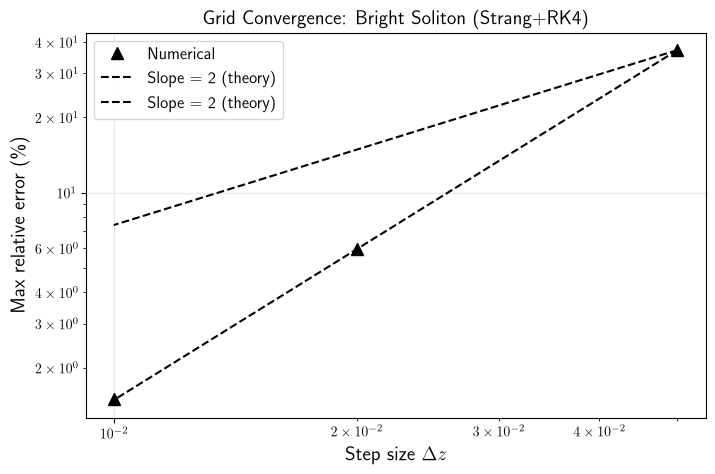

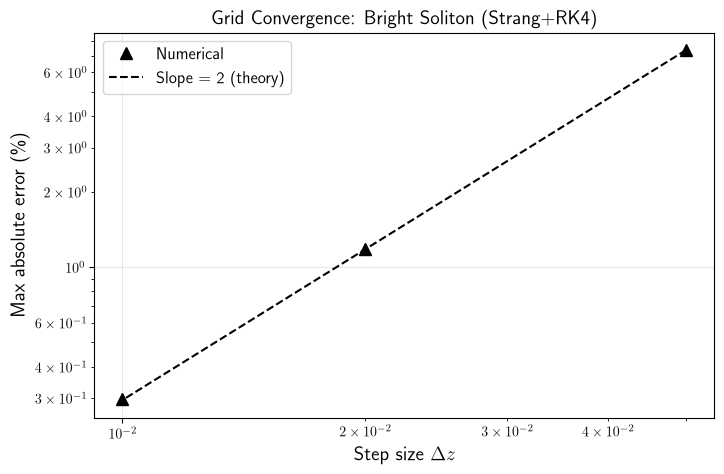

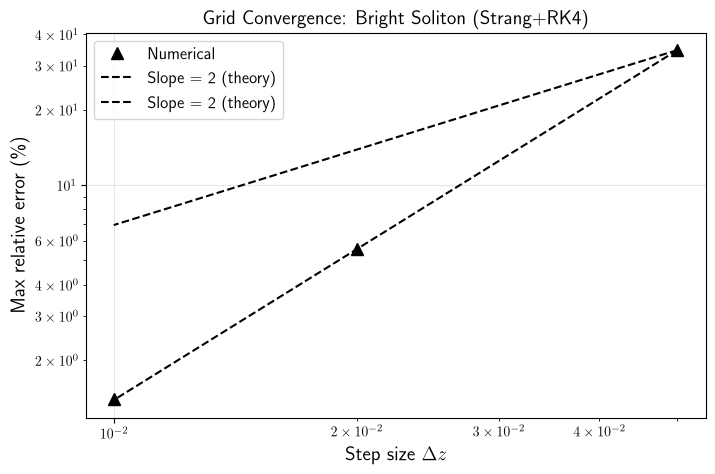

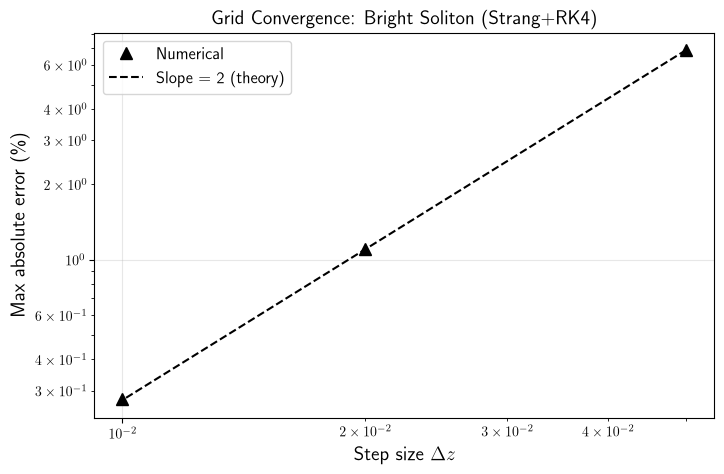

Saved convergence figure and data to ../results/convergence/convergence_6ab71eca4281cd7ed2159d6f841fce572b02d0cb
[-7.28571429 -7.23571429 -7.18571429 -7.13571429 -7.08571429 -7.03571429
 -6.98571429 -6.93571429 -6.88571429 -6.83571429 -6.78571429 -6.73571429
 -6.68571429 -6.63571429 -6.58571429 -6.53571429 -6.48571429 -6.43571429
 -6.38571429 -6.33571429 -6.28571429 -6.23571429 -6.18571429 -6.13571429
 -6.08571429 -6.03571429 -5.98571429 -5.93571429 -5.88571429 -5.83571429
 -5.78571429 -5.73571429 -5.68571429 -5.63571429 -5.58571429 -5.53571429
 -5.48571429 -5.43571429 -5.38571429 -5.33571429 -5.28571429 -5.23571429
 -5.18571429 -5.13571429 -5.08571429 -5.03571429 -4.98571429 -4.93571429
 -4.88571429 -4.83571429 -4.78571429 -4.73571429 -4.68571429 -4.63571429
 -4.58571429 -4.53571429 -4.48571429 -4.43571429 -4.38571429 -4.33571429
 -4.28571429 -4.23571429 -4.18571429 -4.13571429 -4.08571429 -4.03571429
 -3.98571429 -3.93571429 -3.88571429 -3.83571429 -3.78571429 -3.73571429
 -3.6857142

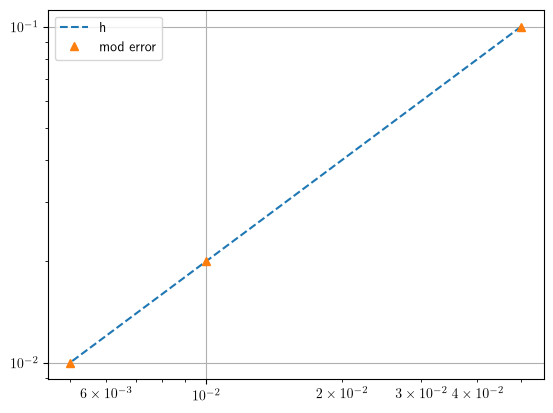

In [91]:
params = {
    "k": 13,
    "c0": 1.4,
    "omega": 5,
    "w0": 0,
    # eq
    "delta_beta": 25,
    "beta2": 0.025,
    "Omega_g": 10,
    "delta": 0.589286,
    "gamma": -0.014,
    "g": 0,
}

t_span = (-2, 20)
z_span = (0, 10)

# good, no looping
convergence_study(
    params,
    t_span=t_span,
    z_span=z_span,
    dz_vals=np.asarray([0.05, 0.02, 0.01]),
    dt_vals=np.full(3, 0.01),
)

# draw_bright_solitons(
#     params,
#     z_grid=Grid(0.01, *z_span),
#     t_grid=Grid(0.01, *t_span),
#     spectral=False,
#     show=True,
# )

t_span = (-2, 2)
z_span = (0, 10)

# looping
# convergence_study(
#     params,
#     t_span=t_span,
#     z_span=z_span,
#     dz_vals=np.asarray([0.05, 0.02, 0.01]),
#     dt_vals=np.full(3, 0.01),
#     show=True,
# )

convergence_study(
    params,
    t_span=t_span,
    z_span=z_span,
    dz_vals=np.asarray([0.05, 0.02, 0.01]),
    dt_vals=np.asarray([0.05, 0.02, 0.01])**2,
    show=True,
)

# draw_bright_solitons(
#     params,
#     z_grid=Grid(0.01, *z_span),
#     t_grid=Grid(0.01, *t_span),
#     spectral=False,
#     show=True,
# )

# looping with smaller time step
# convergence_study(
#     params,
#     t_span=t_span,
#     z_span=z_span,
#     dz_vals=np.asarray([0.05, 0.02, 0.01]),
#     dt_vals=np.full(3, 0.0007),
#     show=True,
# )


t_span = (-2, 10)
z_span = (0, 10)

# mod error
mod_error = []
z_grid = Grid(0.05, *z_span)
dt_grid = np.asarray([0.05, 0.01, 0.005])
for tau in dt_grid:
    t_grid=Grid(tau, *t_span, fill_type='arange')
    PairedEquations.from_params(params).bright_soliton_analytical(
        t_grid.points,
        z=z_grid.points,
        params=params,
        mod_error=mod_error,
    )

# plt.loglog(dt_grid, mod_error[0] * (dt_grid / dt_grid[0]) ** 2, '--', label='$h^2$')
plt.loglog(dt_grid, mod_error[0] * (dt_grid / dt_grid[0]), '--', label='h')
plt.loglog(dt_grid, mod_error, '^', label='mod error')
plt.grid()
plt.legend()

In [92]:
# draw_bright_solitons(params, Grid(0.01, 0, 15), Grid(0.01, 0, 1), spectral=True, show=True)

In [93]:
# params = {
#     "k": 13,
#     "c0": 1.4,
#     "omega": 5,
#     "w0": 0,
#     # "w0": 2 / 1.4,
#     # eq
#     "delta_beta": 25,
#     "beta2": 0.025,
#     "Omega_g": 10,
#     "delta": 0.59,
#     "gamma": -0.014,
#     "g": 0,
# }

# draw_bright_solitons(params, z_grid=Grid(0.01, 0, 15), t_grid=Grid(0.01, 0, 1))